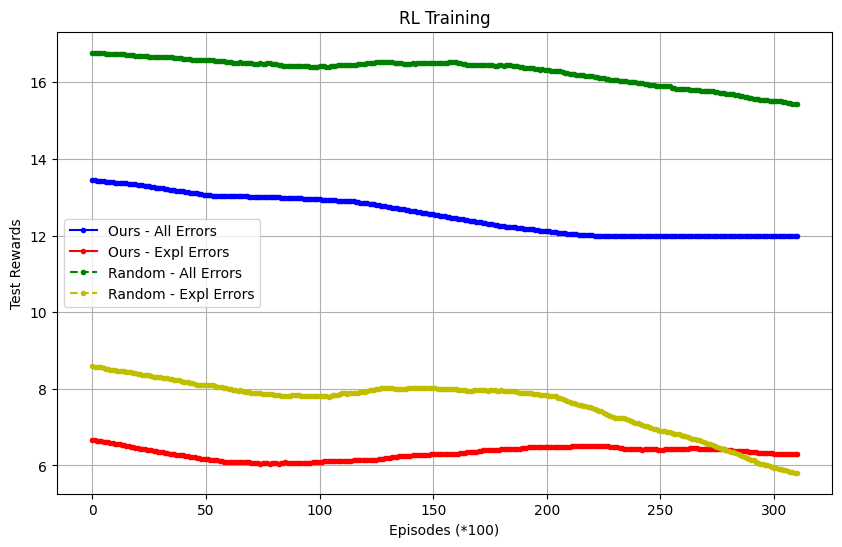

In [49]:
import pickle
import matplotlib.pyplot as plt

with open('../vu2/RL4Auditing/tabular/expl_diversity_statistics_20steps.pkl', 'rb') as file:
    data = pickle.load(file)
# Extract every 1000th element
selected_elements = data["test_reward"]
selected_elements_expl = data["test_reward_expl"]


with open('../vu2/RL4Auditing/tabular/expl_diversity_statistics_30steps.pkl', 'rb') as file:
    data = pickle.load(file)
# Extract every 1000th element
random_selected_elements = data["test_reward"]
random_selected_elements_expl = data["test_reward_expl"]


window_size = 100
averages = []
averages_explain = []

random_averages = []
random_averages_explain = []

# Ensure the list is large enough
if len(random_selected_elements) >= window_size:
    for i in range(window_size, len(random_selected_elements) + 1):
        # Get the last 100 elements ending at index i
        window = selected_elements[i - window_size:i]
        average = sum(window) / window_size
        averages.append(average)
        
        window2 = selected_elements_expl[i - window_size:i]
        average2 = sum(window2) / window_size
        
        averages_explain.append(average2)

        window = random_selected_elements[i - window_size:i]
        average = sum(window) / window_size
        random_averages.append(average)
        
        window2 = random_selected_elements_expl[i - window_size:i]
        average2 = sum(window2) / window_size
        
        random_averages_explain.append(average2)
# Create corresponding x-axis values (iterations)
iterations = list(range(len(random_averages_explain)))

# Plot the selected elements
plt.figure(figsize=(10, 6))
plt.plot(iterations, averages, marker='.', linestyle='-', color='b', label='Ours - All Errors')
plt.plot(iterations, averages_explain, marker='.', linestyle='-', color='r', label='Ours - Expl Errors')
plt.plot(iterations, random_averages, marker='.', linestyle='--', color='g', label='Random - All Errors')
plt.plot(iterations, random_averages_explain, marker='.', linestyle='--', color='y', label='Random - Expl Errors')
plt.xlabel('Episodes (*100)')
plt.ylabel('Test Rewards')
plt.title('RL Training')
plt.legend()
plt.grid()
plt.show()